## Step 1: Analyze dataset structure and statistics

I begin the exploratory analysis by checking the structure of the cleaned dataset and reviewing basic descriptive statistics.

This helps confirm the number of records and variables available for analysis, the data types of important columns, and the distribution of numerical fields such as `release_year`, `year_added`, `movie_minutes`, and `tv_seasons`.

I also check the number of unique titles, content types, and ratings to understand the main dimensions of the dataset before creating visualizations.

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Load the cleaned dataset
df_eda = pd.read_csv("../data/netflix_clean.csv")

print("Dataset shape:", df_eda.shape)

print("\nData types:")
display(df_eda.dtypes)

print("\nDescriptive statistics:")
display(
    df_eda[
        [
            "release_year",
            "year_added",
            "movie_minutes",
            "tv_seasons"
        ]
    ].describe()
)

print("\nNumber of unique titles:", df_eda["title"].nunique())

print("\nContent types:")
display(df_eda["type"].value_counts())

print("\nRatings:")
display(df_eda["rating"].value_counts())

Dataset shape: (8786, 26)

Data types:


show_id                  object
type                     object
title                    object
director                 object
country                  object
date_added               object
release_year              int64
rating                   object
duration                 object
listed_in                object
year_added                int64
month_added               int64
month_name               object
duration_value          float64
duration_unit            object
movie_minutes           float64
tv_seasons              float64
country_list             object
genre_list               object
director_list            object
n_countries               int64
n_genres                  int64
n_directors               int64
audience                 object
years_to_add              int64
added_before_release       bool
dtype: object


Descriptive statistics:


,release_year,year_added,movie_minutes,tv_seasons
count,8786.000000,8786.000000,6123.000000,2663.000000
mean,2014.181766,2018.873663,99.572595,1.752159
std,8.827137,1.573897,28.282615,1.550844
min,1925.000000,2008.000000,3.000000,1.000000
25%,2013.000000,2018.000000,87.000000,1.000000
50%,2017.000000,2019.000000,98.000000,1.000000
75%,2019.000000,2020.000000,114.000000,2.000000
max,2021.000000,2021.000000,312.000000,17.000000



Number of unique titles: 8786

Content types:


type
Movie      6123
TV Show    2663
Name: count, dtype: int64


Ratings:


rating
TV-MA        3204
TV-14        2155
TV-PG         861
R             798
PG-13         490
TV-Y7         333
TV-Y          306
PG            287
TV-G          220
Not Rated      82
G              41
TV-Y7-FV        6
NC-17           3
Name: count, dtype: int64

### Preparing list-based columns for EDA

The cleaned CSV stores list-based columns as text because CSV does not preserve Python list objects.

I therefore convert `country_list`, `genre_list`, and `director_list` back into Python lists before using them for analysis. This allows each country, genre, or director to be analysed separately when a title contains multiple values.

In [41]:
# Convert list-like text back into Python lists

for col in ["country_list", "genre_list", "director_list"]:
    df_eda[col] = df_eda[col].apply(ast.literal_eval)

print("List column types:")

for col in ["country_list", "genre_list", "director_list"]:
    print(f"{col}: {type(df_eda[col].iloc[0])}")

List column types:
country_list: <class 'list'>
genre_list: <class 'list'>
director_list: <class 'list'>


## Step 2: Study content distribution by type

I next examine the distribution of Movies and TV Shows in the dataset.

This shows which type of content makes up the larger share of the Netflix catalogue and provides a simple comparison between the two content categories.

In [42]:
# Count each content type

type_counts = df_eda["type"].value_counts()

print("Content type counts:")
display(type_counts)


# Calculate percentages

type_percentages = (
    df_eda["type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nContent type percentages:")
display(type_percentages)


# Combine counts and percentages

type_distribution = pd.DataFrame({
    "count": type_counts,
    "percentage": type_percentages
})

print("\nContent distribution:")
display(type_distribution)

Content type counts:


type
Movie      6123
TV Show    2663
Name: count, dtype: int64


Content type percentages:


type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


Content distribution:


,count,percentage
type,,
Movie,6123,69.69
TV Show,2663,30.31


### Step 2 Finding

Movies make up the majority of the dataset, with 6,123 titles (69.69%), while TV Shows account for 2,663 titles (30.31%).

This means the cleaned dataset contains more than twice as many Movies as TV Shows. The difference in content type should be considered when comparing other characteristics, such as ratings, release years, and duration.

## Step 3: Identify top countries and categories

I next examine which countries and content categories appear most frequently in the dataset.

For countries, I use the structured `country_list` created during data cleaning and exclude missing values. For categories, I use `genre_list`, which contains the individual categories associated with each title.

Because some country labels may be unreliable, particularly the Pakistan label identified during data cleaning, country rankings are interpreted as patterns **in this dataset** rather than verified real-world country distributions.

In [43]:
# Top countries

country_counts_eda = (
    df_eda["country_list"]
    .explode()
    .dropna()
    .value_counts()
)

print("Top 10 countries in the dataset:")
display(country_counts_eda.head(10))


# Top individual categories / genres

genre_counts_eda = (
    df_eda["genre_list"]
    .explode()
    .dropna()
    .value_counts()
)

print("\nTop 10 categories:")
display(genre_counts_eda.head(10))

Top 10 countries in the dataset:


country_list
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


Top 10 categories:


genre_list
International Movies        2751
Dramas                      2423
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

### Step 3 Finding

The United States has the largest country count in the dataset, with 3,240 titles, followed by India with 1,056 and the United Kingdom with 638. Pakistan appears fourth with 420 titles.

For categories, International Movies is the most common category, appearing in 2,751 titles, followed by Dramas with 2,423 and Comedies with 1,673.

Category counts can exceed the total number of titles because a single title can belong to multiple categories.

The country results should be interpreted as patterns **in this dataset**. In particular, the Pakistan label was identified during data cleaning as potentially unreliable, so it should not be treated as a verified real-world country distribution.

## Step 4: Create visualizations for key metrics

### 4.1 Movies vs TV Shows

I first visualize the distribution of Movies and TV Shows to make the difference in content type easier to interpret.

A bar chart is appropriate here because the variable is categorical and the main goal is to compare the number of titles in each content type.

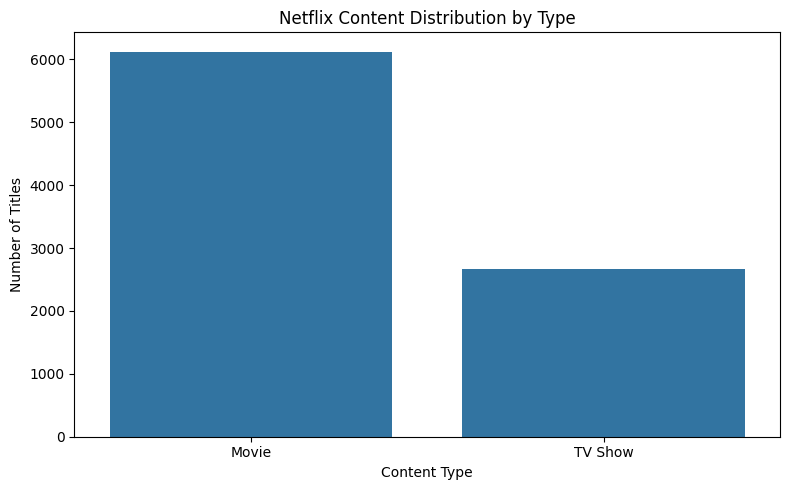

In [44]:
# Visualize the distribution of Movies and TV Shows

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_eda,
    x="type"
)

plt.title("Netflix Content Distribution by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

### Visualization Finding

The chart shows that Movies make up a substantially larger share of the dataset than TV Shows. There are 6,123 Movies compared with 2,663 TV Shows, confirming that Movies account for approximately 70% of the cleaned dataset.

This difference should be considered when interpreting other results because some characteristics may naturally be more strongly represented by Movies simply because there are more Movie records.

### 4.2 Top 10 Countries

I next visualize the countries with the highest number of titles in the dataset.

A horizontal bar chart makes the country names easier to read and allows the differences in title counts to be compared clearly.

The results are interpreted as country patterns **in this dataset**. As identified during data cleaning, the Pakistan label appears questionable for some records, so this result should be treated with caution.

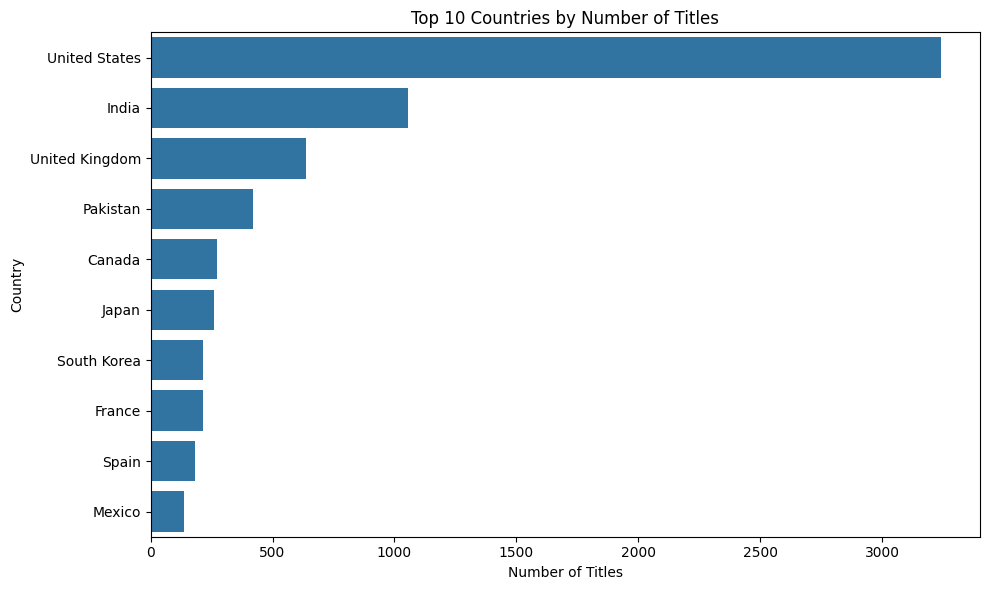

In [45]:
# Get the top 10 countries

top_countries = country_counts_eda.head(10)

# Plot the results

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

### Visualization Finding

The United States has the highest number of titles in the dataset, with 3,240 titles, followed by India with 1,056 and the United Kingdom with 638.

Pakistan ranks fourth with 420 titles. However, this result should be interpreted cautiously because the country field was identified during data cleaning as containing potentially inaccurate Pakistan labels.

Overall, the chart shows that the United States has a substantially larger representation than the other countries in the top 10.

### 4.3 Top 10 Categories

I next visualize the most common content categories in the dataset.

Because a title can belong to more than one category, the categories are not mutually exclusive. Therefore, the counts represent the number of titles associated with each category rather than the number of unique titles in each category.

A horizontal bar chart is used to make the category names easier to compare.

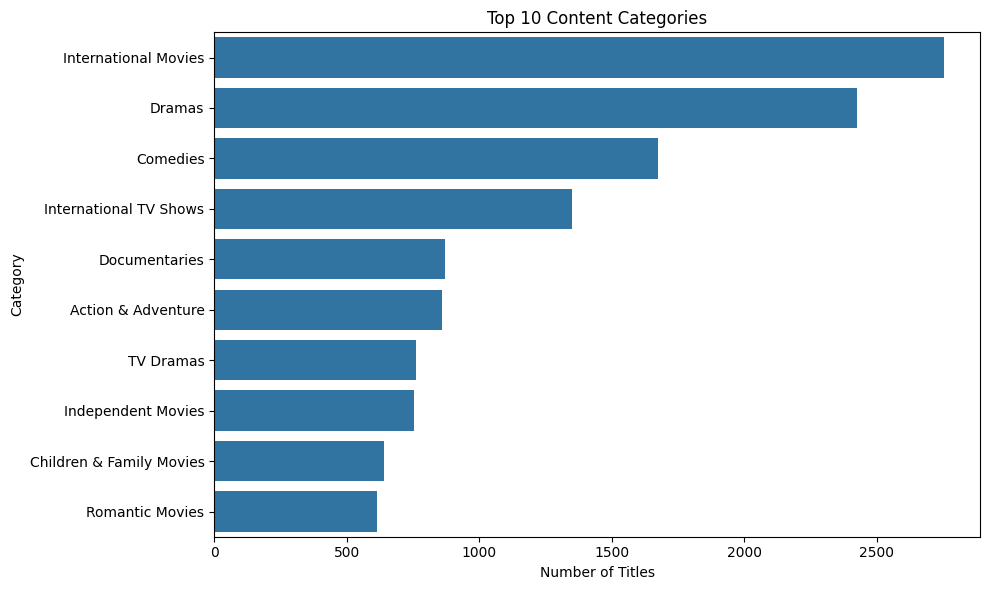

In [46]:
# Get the top 10 categories

top_genres = genre_counts_eda.head(10)

# Plot the results

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Content Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

### Visualization Finding

International Movies is the most common category in the dataset, appearing in 2,751 titles, followed by Dramas with 2,423 and Comedies with 1,673.

The results show a strong representation of international and drama-related content. However, the categories overlap because individual titles can belong to multiple categories, so the counts should not be added together to estimate the total number of titles.

### 4.4 Content Added to Netflix Over Time

I next examine how the number of titles added to the Netflix catalogue changed over time.

I use `year_added`, which was derived from the original `date_added` field during data cleaning.

The dataset contains only part of 2021, with the latest recorded date being September 25, 2021. To avoid comparing an incomplete year with full years, the main trend visualization uses complete years from 2008 to 2020.

In [47]:
# Count titles added each year

yearly_additions = (
    df_eda[
        df_eda["year_added"] <= 2020
    ]
    .groupby("year_added")
    .size()
)

print("Titles added by year (complete years):")
display(yearly_additions)

Titles added by year (complete years):


year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1647
2019    2013
2020    1879
dtype: int64

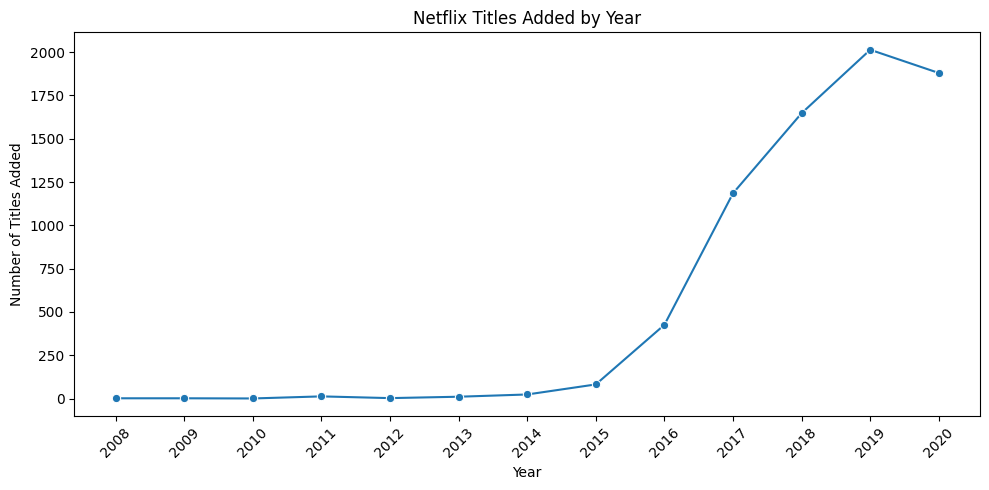

In [48]:
# Plot titles added by year

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=yearly_additions.index,
    y=yearly_additions.values,
    marker="o"
)

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")

plt.xticks(yearly_additions.index, rotation=45)

plt.tight_layout()
plt.show()

### Visualization Finding

The number of titles added to the dataset increased substantially from 2015 onward, rising from 82 titles in 2015 to 2,013 titles in 2019.

The number of additions then declined slightly to 1,879 titles in 2020. Overall, the data shows a strong expansion in catalogue additions during the later years of the period.

The incomplete 2021 data was excluded from this main comparison because the dataset only contains records through September 25, 2021. Therefore, 2021 should not be directly compared with the complete years.

### 4.5 Movie Runtime Distribution

I next examine the distribution of movie runtimes in minutes.

The analysis is limited to Movies because TV Shows are measured using the number of seasons rather than runtime in minutes.

A histogram is used to show how movie runtimes are distributed and where most movies are concentrated.

In [49]:
# Select movie runtimes

movie_runtime = df_eda.loc[
    df_eda["type"] == "Movie",
    "movie_minutes"
].dropna()

print("Movie runtime statistics:")
display(movie_runtime.describe())

Movie runtime statistics:


count    6123.000000
mean       99.572595
std        28.282615
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: movie_minutes, dtype: float64

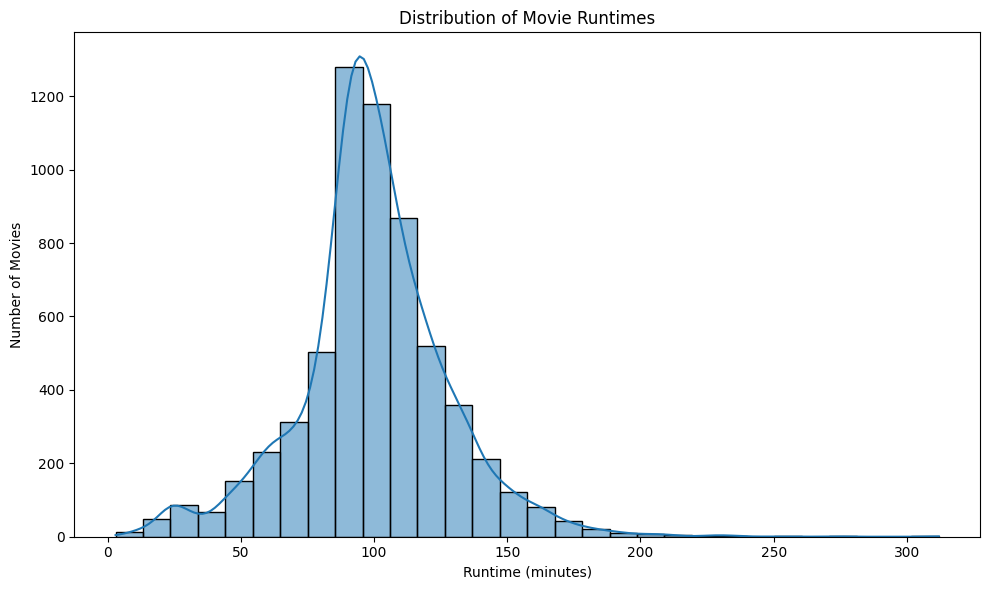

In [50]:
# Plot movie runtime distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    movie_runtime,
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

### Visualization Finding

Movie runtimes are concentrated around approximately 90 to 120 minutes. The median runtime is 98 minutes, while the middle 50% of movies fall between 87 and 114 minutes.

The distribution also has a wider range, from 3 to 312 minutes. Some very short movies are present, but they were retained during data cleaning because a short runtime does not by itself indicate an invalid record.

Overall, the dataset suggests that a typical movie is around 100 minutes long, while a smaller number of titles have substantially shorter or longer runtimes.

## Step 5: Summarize findings

The exploratory analysis provides several key insights into the cleaned Netflix dataset.

- Movies are the dominant content type, with 6,123 titles (69.69%) compared with 2,663 TV Shows (30.31%).
- The United States has the largest number of titles in the dataset, followed by India and the United Kingdom. Pakistan also appears among the top countries, although its records should be interpreted cautiously because potential country-label inconsistencies were identified during data cleaning.
- International Movies, Dramas, and Comedies are the most frequently occurring categories. Category counts overlap because a single title can belong to multiple categories.
- The number of titles added increased substantially from 2015 onward, reaching 2,013 additions in 2019 before declining slightly to 1,879 in 2020. The incomplete 2021 data was excluded from the main year comparison.
- Movie runtimes are generally concentrated around 90–120 minutes, with a median runtime of 98 minutes and a middle 50% between 87 and 114 minutes.
- TV-MA is the most common rating in the dataset, followed by TV-14.

Overall, the EDA shows that the dataset is dominated by Movies, contains a strong representation of international and drama-related categories, and experienced a substantial increase in recorded catalogue additions during the later years of the dataset. These findings provide a basis for more detailed analysis in subsequent tasks.